# Render the Dreadnoughts Using the Game Data

In [405]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:70% !important; }</style>"))

In [406]:
resize = lambda img,factor: img.resize((int(img.width * factor), int(img.height * factor)), Image.NEAREST)

### Load the Source Code

In [407]:
source_file = "uridium-listing-game-logic.txt"
input_file = open(source_file,'r')
source_lines = [l.split('\t') for l in input_file.readlines()]

segments = []
segment_bytes = []
segment_source_lines = []
segment = ""
for l in source_lines:
    if len(l) == 1:
        if l[0].startswith('#'):
            if segment_bytes:
                segments += [(segment, segment_bytes,segment_source_lines)]
            segment_bytes = []
            segment_source_lines = []
            segment = l[0][2:].strip()
        continue
    if len(l) != 4:
        continue
    address, bytes_string, assembly_line, source_line = l
    segment_bytes += bytes_string.split()
    segment_source_lines += [source_line]
segments += [(segment, segment_bytes,segment_source_lines)]

In [408]:
for s,bs,_ in segments:
    print(s, len(bs))

Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369


In [409]:
!mkdir -p game_logic_map

### Title Screen

In [410]:
SCALER = 8

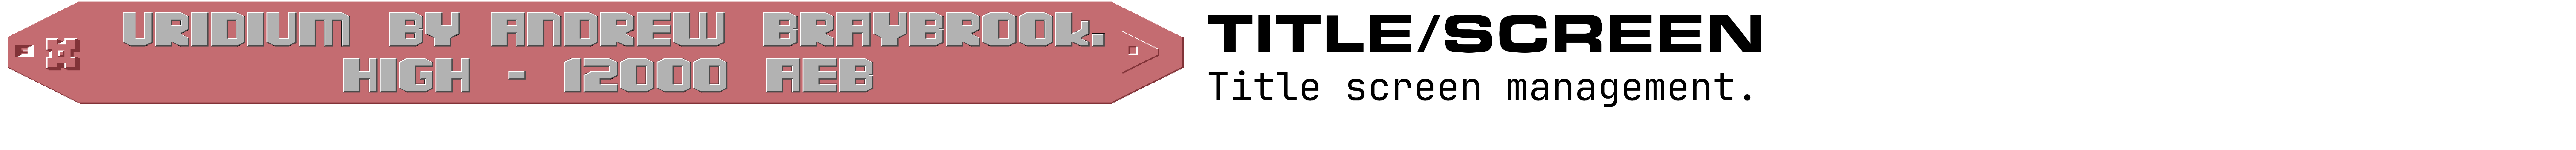

In [427]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Enter Level Sequence 96
Main Loop 120
Music and Sound 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 0

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 15
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "TITLE/SCREEN"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Title screen management.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
x,y = 800,80
for xo, yo, f in [(0, 0, "scroller_title/uridiumby.png"), (2400, 0, "scroller_title/andrew.png"), (-1200, 300, "scroller_title/hiscore.png"),]:
    x+=xo
    y+=yo
    decor_png = Image.open(f)
    decor_png = resize(decor_png, 0.7)
    img.paste(decor_png, (x,y), mask=decor_png)

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/1_title_screen.png")
img

### Spinning Ship

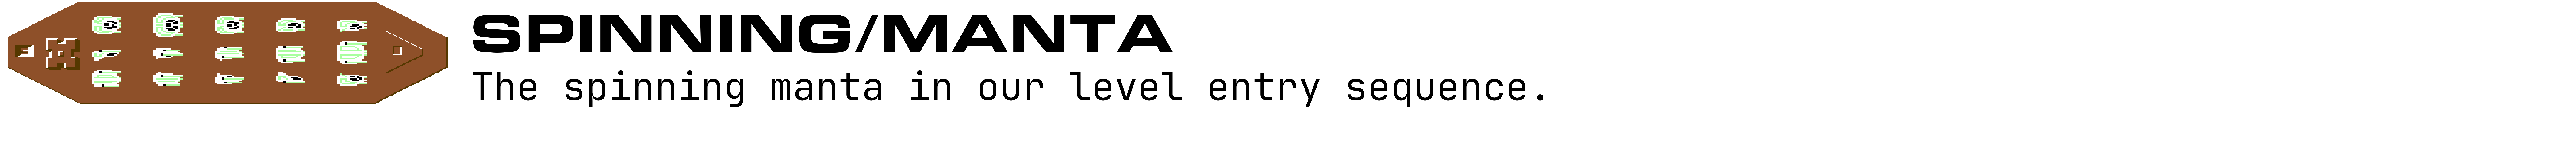

In [412]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Enter Level Sequence 96
Main Loop 120
Music and Sound 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 1

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 3
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "SPINNING/MANTA"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
The spinning manta in our level entry sequence.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
x,y = 600,80
for i,f in enumerate(range(0x40,0x4F)):
    if i > 0 and i % 5 == 0:
        y += 180
        x = 600
    f_hex = f"{f:02X}"
    decor_png = Image.open(f"manta_sprites/{level}_{f_hex}.png")
    decor_png = resize(decor_png, 8)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=400

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/2_spinning_manta.png")
img

### Main Loop

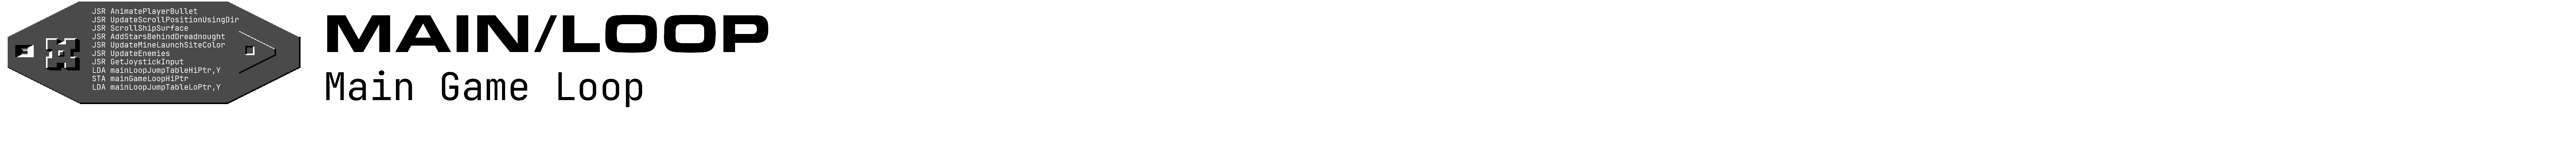

In [413]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 2

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
level = 2
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "MAIN/LOOP"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Main Game Loop
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add the source text to the surface layer
"""
x,y = 360,40
num_lines = 10
for f in range(0,10,num_lines):
    src_lines = '\n'.join([x.rstrip()[:40] for x in segment_source_lines[f:f + num_lines]])
    src_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 50)
    draw = ImageDraw.Draw(img)
    draw.text((x, y), src_lines, font=src_fnt, fill="white")
    x+=1000

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/3_main_loop.png")
img

### Game Over

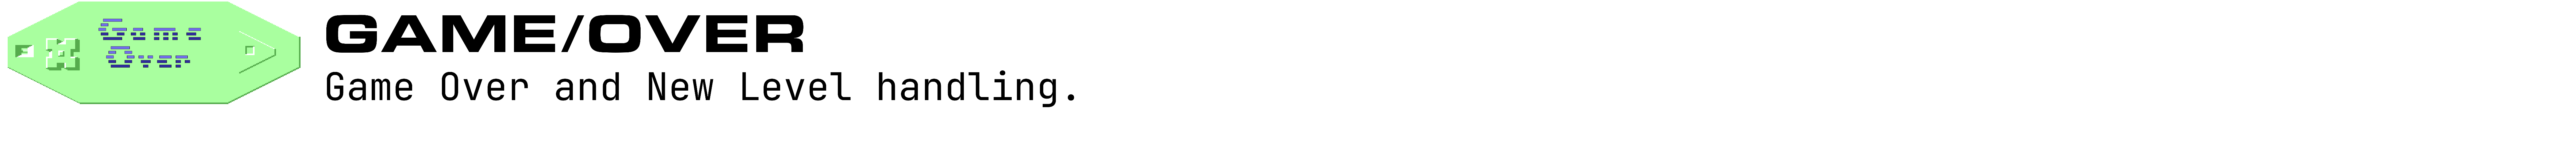

In [414]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 3
level = 5

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "GAME/OVER"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Game Over and New Level handling.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
sentence = """Game Over"""
chars = []
for char in [x for x in sentence if x != '\n']:
    chars += [f"./text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_{char}_outlined.png"]
    
x,y = 600,80
for i,f in enumerate(chars):
    if i > 0 and i % 5 == 0:
        y += 180
        x = 650
    decor_png = Image.open(f)
    decor_png = resize(decor_png, 1)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=decor_png.width +1

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/4_game_over.png")
img

### Play Music

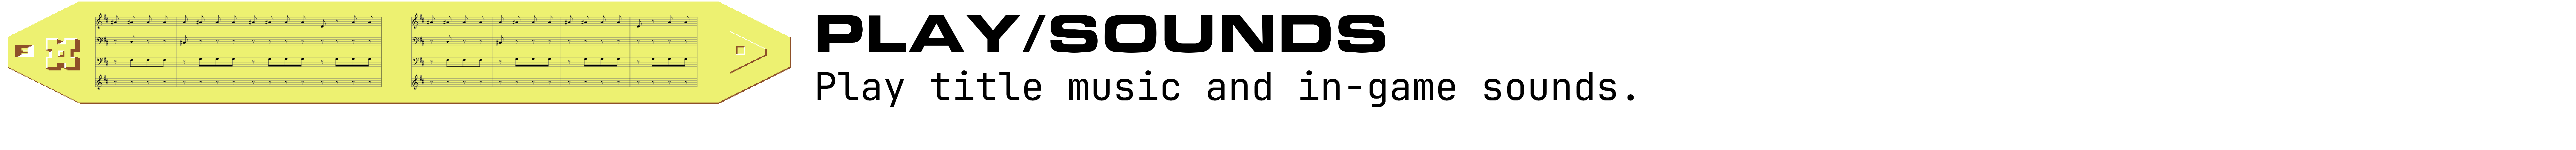

In [415]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 4
level = 6

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "PLAY/SOUNDS"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Play title music and in-game sounds.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
x,y = 600,50
for i,f in enumerate(range(0,2)):
    decor_png = Image.open(f"sheet_music/title_no_0_page_1001.png")
    decor_png = resize(decor_png, 2.3)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=decor_png.width + 150


img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/5_play_sounds.png")
img

### Mini Game

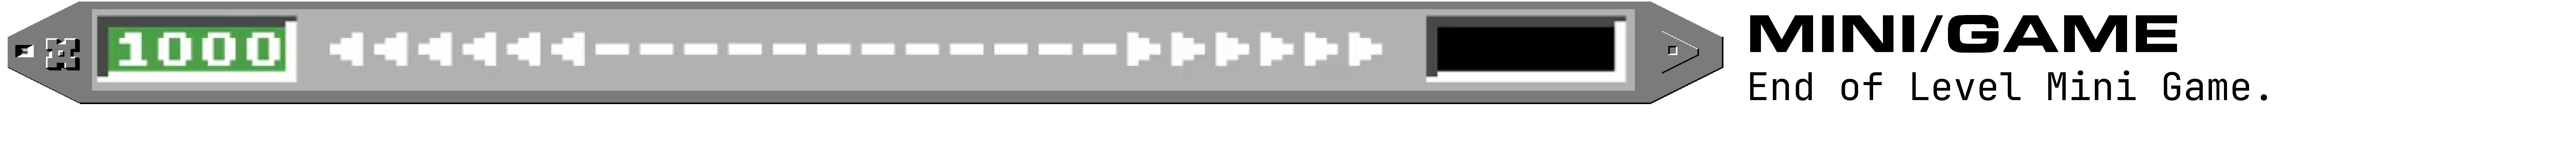

In [416]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 5
level = 8

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "MINI/GAME"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
End of Level Mini Game.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
decor_png = Image.open(f"minigame/mini5.png")
decor_png = resize(decor_png, 8.6)
img.paste(decor_png, (600,60))


img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/6_mini_game.png")
img

### Destruction Sequence

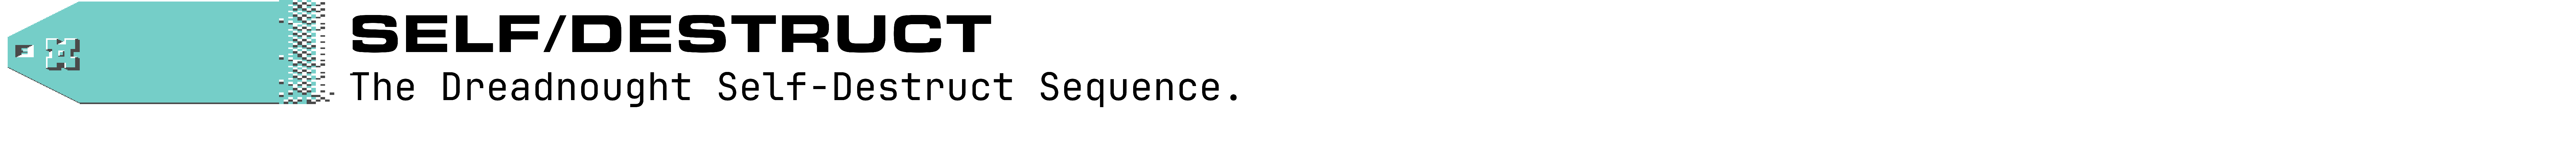

In [417]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 6
level = 7

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width


"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)



"""
Draw the label
"""
label_text = "SELF/DESTRUCT"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
The Dreadnought Self-Destruct Sequence.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
import random
for y in range(0,600,40):
    a,b,c = random.choice(['F9','FA']),random.choice(['FB','FC']),random.choice(['FD','FE'])
    cimg = Image.open(f"selfdestruct/trigrams/{level}_{a}_{b}_{c}_{random.randint(0,1)}_no_highlight.png")
    cimg = resize(cimg,1)
    img.paste(cimg, (x-300, y))

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/7_destruct_sequence.png")
img

### Hi Score

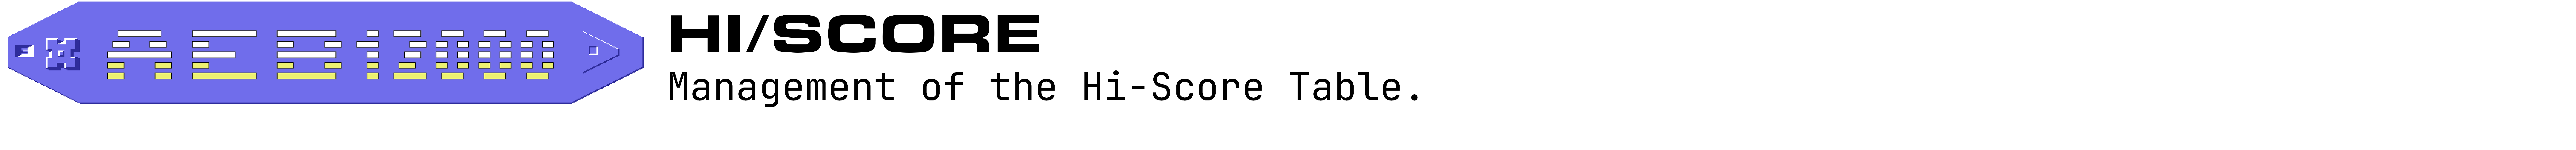

In [418]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 7
level = 9

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "HI/SCORE"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Management of the Hi-Score Table.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
sentence = """AEB12000"""
chars = []
for char in [x for x in sentence if x != '\n']:
    chars += [f"./text_character_set_diagrams/composite_character_sets_alphanumeric/c64_white_c64_yellow_{char}_outlined.png"]
    
x,y = 600,100
for i,f in enumerate(chars):
    decor_png = Image.open(f)
    decor_png = resize(decor_png, 2.3)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=decor_png.width +1


img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/8_hi_score.png")
img

### Enemy Management

In [419]:
enemy_sprites = f"""meanie_sprites/{level}_MEANIE_00.png
meanie_sprites/{level}_MEANIE_01.png
meanie_sprites/{level}_MEANIE_02.png
meanie_sprites/{level}_MEANIE_03.png
meanie_sprites/{level}_MEANIE_04.png
meanie_sprites/{level}_MEANIE_05.png
meanie_sprites/{level}_MEANIE_06.png
meanie_sprites/{level}_MEANIE_07.png
meanie_sprites/{level}_MEANIE_08.png
meanie_sprites/{level}_MEANIE_09.png
meanie_sprites/{level}_MEANIE_0A.png
meanie_sprites/{level}_MEANIE_0B.png
meanie_sprites/{level}_MEANIE_0C.png
meanie_sprites/{level}_MEANIE_0D.png
meanie_sprites/{level}_MEANIE_0E.png
meanie_sprites/{level}_MEANIE_0F.png
meanie_sprites/{level}_MEANIE_10.png
meanie_sprites/{level}_MEANIE_11.png
meanie_sprites/{level}_MEANIE_12.png
meanie_sprites/{level}_MEANIE_13.png
meanie_sprites/{level}_MEANIE_14.png
meanie_sprites/{level}_MEANIE_15.png
meanie_sprites/{level}_MEANIE_16.png
meanie_sprites/{level}_MEANIE_17.png
meanie_sprites/{level}_MEANIE_18.png
meanie_sprites/{level}_MEANIE_19.png
meanie_sprites/{level}_MEANIE_1A.png
meanie_sprites/{level}_MEANIE_1B.png
meanie_sprites/{level}_MEANIE_1C.png
meanie_sprites/{level}_MEANIE_1D.png
meanie_sprites/{level}_MEANIE_1E.png
meanie_sprites/{level}_MEANIE_1F.png
""".split('\n')[:-1]

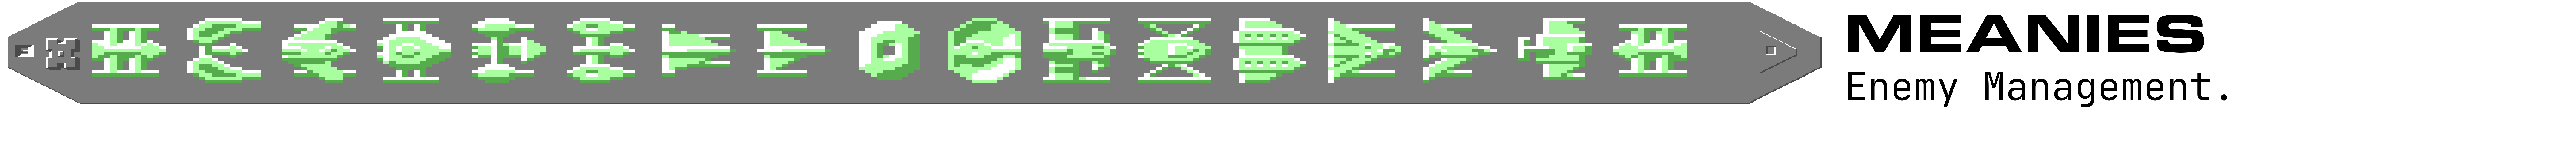

In [420]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 8
level = 10

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "MEANIES"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Enemy Management.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
from itertools import chain
x,y = 600,120
x_orig = x
for i,f in enumerate(enemy_sprites[:17]):
    draw = ImageDraw.Draw(img)
    decor_png = Image.open(f)
    decor_png = resize(decor_png, 20)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=620

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/9_enemy_management.png")
img

### Demo Mode

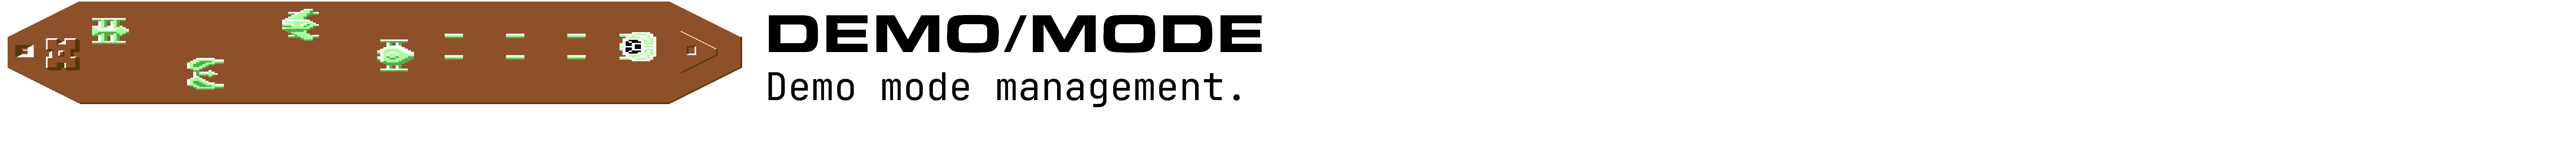

In [421]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 9
level = 11

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "DEMO/MODE"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Demo mode management.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""

# Manta SPrite
decor_png = Image.open(f"manta_sprites/{level}_MANTA_LEFT_9.png")
decor_png = resize(decor_png, 10)
img.paste(decor_png, (x-800,y+200), mask=decor_png)

# Bullet SPrites
for o in [1200,1600,2000]:
    decor_png = Image.open(f"meanie_bullet_sprites/{level}_BULLET_NARROW.png")
    decor_png = resize(decor_png, 10)
    img.paste(decor_png, (x-o,y+200), mask=decor_png)

enemy_sprites = f"""meanie_sprites/{level}_MEANIE_00.png
meanie_sprites/{level}_MEANIE_01.png
meanie_sprites/{level}_MEANIE_02.png
meanie_sprites/{level}_MEANIE_03.png
""".split('\n')[:-1]

from itertools import chain
x,y = 600,120
x_orig = x
for i,(f,y) in enumerate(zip(enemy_sprites, [random.randint(10, 400) for _ in range(10)])):
    decor_png = Image.open(f)
    decor_png = resize(decor_png, 10)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=620



img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/10_demo_mode.png")
img

### In Game Screen

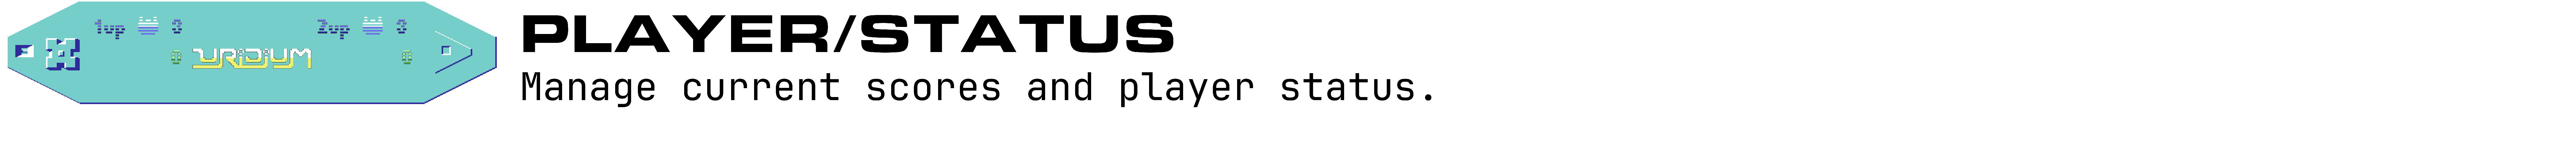

In [422]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 10
level = 12

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "PLAYER/STATUS"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Manage current scores and player status.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
chars = [
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_1_outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_u_outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_p_outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_ltblue_7A.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_3_outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_2_outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_u_outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_p_outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_ltblue_7A.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_ _outlined.png",
"text_character_set_diagrams/composite_character_sets_alphanumeric/c64_ltblue_c64_blue_3_outlined.png",

"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_ltgreen_c64_green_00_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"banner_diagrams/c64_white_c64_yellow_logo.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_white_c64_yellow_30_outlined.png",
"text_character_set_diagrams/composite_character_sets/c64_ltgreen_c64_green_00_outlined.png",
]

x,y = 600,100
for i,f in enumerate(chars):
    if i == 30:
        y+=200
        x = 600
    decor_png = Image.open(f)
    decor_png = resize(decor_png, 0.65)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=decor_png.width -5


img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/11_in_game.png")
img

### Manta Management

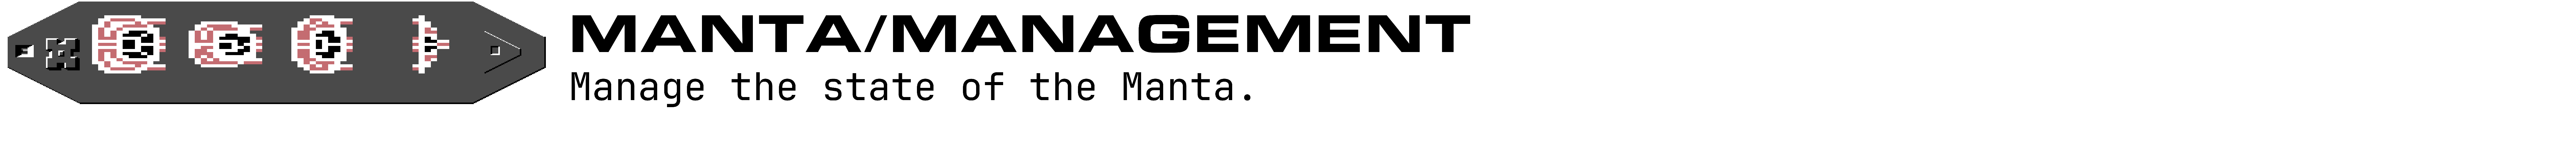

In [423]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 11
level = 13

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "MANTA/MANAGEMENT"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Manage the state of the Manta.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
manta_sprites = f"""manta_sprites/{level}_MANTA1.png
manta_sprites/{level}_MANTA_2.png
manta_sprites/{level}_MANTA_FLIP_0.png
manta_sprites/{level}_MANTA_FLIP_10.png
manta_sprites/{level}_MANTA_FLIP_11.png
manta_sprites/{level}_MANTA_FLIP_12.png
manta_sprites/{level}_MANTA_FLIP_13.png
manta_sprites/{level}_MANTA_FLIP_1.png
manta_sprites/{level}_MANTA_FLIP_2.png
manta_sprites/{level}_MANTA_FLIP_3.png
manta_sprites/{level}_MANTA_FLIP_4.png
manta_sprites/{level}_MANTA_FLIP_5.png
manta_sprites/{level}_MANTA_FLIP_6.png
manta_sprites/{level}_MANTA_FLIP_7.png
manta_sprites/{level}_MANTA_FLIP_8.png
manta_sprites/{level}_MANTA_FLIP_9.png
manta_sprites/{level}_MANTA_LEFT_0.png
manta_sprites/{level}_MANTA_LEFT_10.png
manta_sprites/{level}_MANTA_LEFT_11.png
manta_sprites/{level}_MANTA_LEFT_12.png
manta_sprites/{level}_MANTA_LEFT_13.png
manta_sprites/{level}_MANTA_LEFT_14.png
manta_sprites/{level}_MANTA_LEFT_15.png
manta_sprites/{level}_MANTA_LEFT_1.png
manta_sprites/{level}_MANTA_LEFT_2.png
manta_sprites/{level}_MANTA_LEFT_3.png
manta_sprites/{level}_MANTA_LEFT_4.png
manta_sprites/{level}_MANTA_LEFT_5.png
manta_sprites/{level}_MANTA_LEFT_6.png
manta_sprites/{level}_MANTA_LEFT_7.png
manta_sprites/{level}_MANTA_LEFT_8.png
manta_sprites/{level}_MANTA_LEFT_9.png
manta_sprites/{level}_MANTA.png
manta_sprites/{level}_MANTA_RIGHT_10.png
manta_sprites/{level}_MANTA_RIGHT_11.png
manta_sprites/{level}_MANTA_RIGHT_12.png
manta_sprites/{level}_MANTA_RIGHT_13.png
manta_sprites/{level}_MANTA_RIGHT_14.png
manta_sprites/{level}_MANTA_RIGHT_15.png
manta_sprites/{level}_MANTA_RIGHT_3.png
manta_sprites/{level}_MANTA_RIGHT_4.png
manta_sprites/{level}_MANTA_RIGHT_5.png
manta_sprites/{level}_MANTA_RIGHT_6.png
manta_sprites/{level}_MANTA_RIGHT_7.png
manta_sprites/{level}_MANTA_RIGHT_8.png
manta_sprites/{level}_MANTA_RIGHT_9.png
""".split('\n')[:-1]

x,y = 600,80
x_orig = x
for i,f in enumerate(manta_sprites[:4]):
    decor_png = Image.open(f)
    decor_png = resize(decor_png,20)
    img.paste(decor_png, (x,y), mask=decor_png)
    x+=630


img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/12_manta_state.png")
img

### Drop Ship Deployment

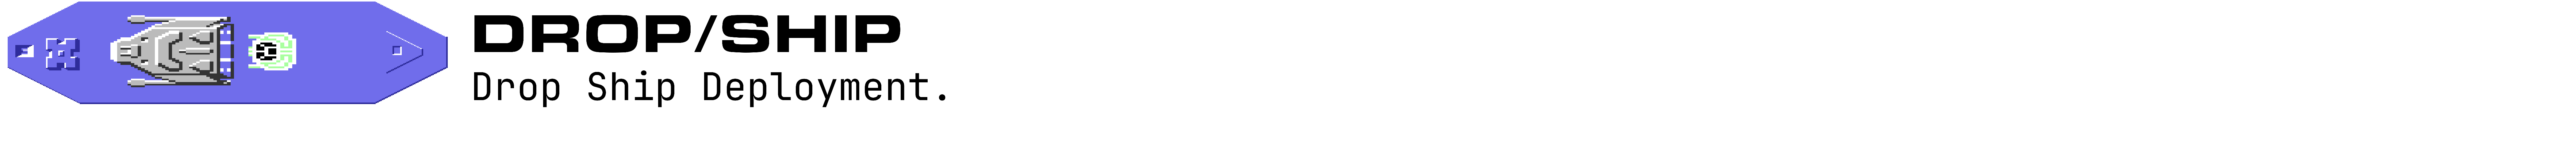

In [424]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 12
level = 14

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "DROP/SHIP"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Drop Ship Deployment.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
decor_png = Image.open(f"dropship_sprites/dropship.png")
decor_png = resize(decor_png, 1.4)
img.paste(decor_png, (x-2200,y+100), mask=decor_png)

decor_png = Image.open(f"manta_sprites/{level}_MANTA_LEFT_9.png")
decor_png = resize(decor_png, 13)
img.paste(decor_png, (x-1300,y+200), mask=decor_png)

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/13_drop_ship_deployment.png")
img

### Manta Firing

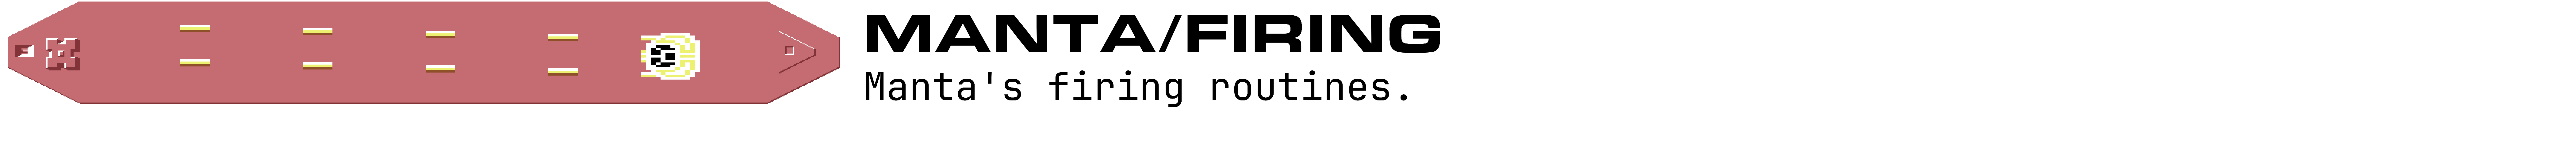

In [425]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 13
level = 15

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "MANTA/FIRING"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Manta's firing routines.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
# Bullet SPrites
yo = 20
for o in range(2000,5000,800):
    decor_png = Image.open(f"meanie_bullet_sprites/{level}_BULLET_NARROW.png")
    decor_png = resize(decor_png, 16)
    img.paste(decor_png, (x-o,y+210-yo), mask=decor_png)
    yo+=20

decor_png = Image.open(f"manta_sprites/{level}_MANTA_LEFT_9.png")
decor_png = resize(decor_png, 16)
img.paste(decor_png, (x-1300,y+200), mask=decor_png)

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/14_manta_firing.png")
img

### Scrolling the Dreadnought

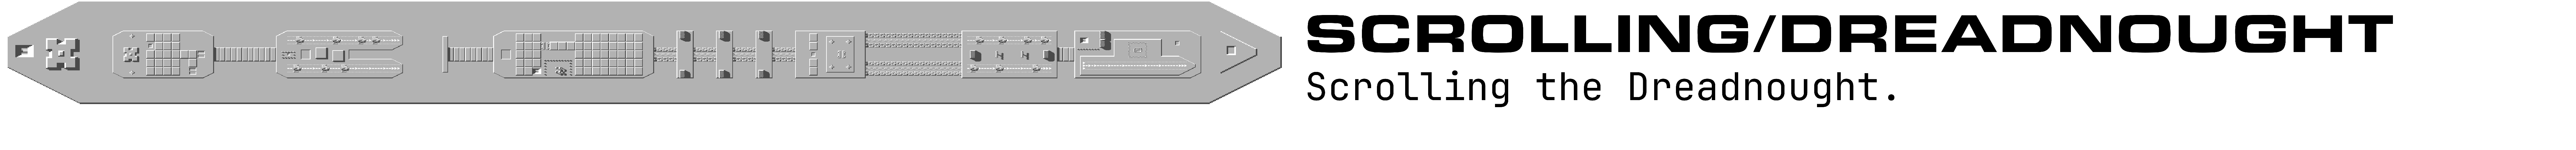

In [426]:
from PIL import Image, ImageFont,ImageDraw

"""
Title Screen 336
Start Sequence 96
Main Loop 57
Game Over Detection 63
Play Music 210
Mini Game 519
Destruction Sequence 93
Hi Score 174
Enemy Management 546
Title Screen and Demo Mode 204
Update In-Game Screen 123
Manta Management 135
Drop Ship Deployment 102
Manta Firing 228
Drawing and Scrolling the Dreadnought 369
"""

SEGMENT_NUMBER = 14
level = 1

LINE_HEIGHT = 680
WIDTH = 30 * 560
HEIGHT = (LINE_HEIGHT + 300) 
img = Image.new( 'RGBA', (WIDTH, HEIGHT))

BYTES_PER_LINE =16
x,y = 0,0

segment_name, segment_bytes, segment_source_lines = segments[SEGMENT_NUMBER]
segment_len =  len(segment_bytes)
num_lines = int(segment_len/BYTES_PER_LINE)

"""
Create the base layer
"""
open_segment0_png = Image.open(f"surface_structures/{level}_138.png")
open_segment_png = Image.open(f"surface_structures/{level}_4.png")
close_segment0_png = Image.open(f"surface_structures/{level}_139.png")
close_segment_png = Image.open(f"surface_structures/{level}_6.png")
open_line_png = Image.open(f"surface_structures/{level}_1.png")
close_line_png = Image.open(f"surface_structures/{level}_3.png")
mid_line_png = Image.open(f"surface_structures/{level}_2.png")


"""
Front Section
"""
x += open_segment0_png.width
img.paste(open_segment_png, (x,y), mask=open_segment_png)
img.paste(open_segment0_png, (x - open_segment0_png.width + 40, y + int((LINE_HEIGHT-open_segment0_png.height)/2)), mask=open_segment0_png)
x += open_segment_png.width

"""
Mid Section
"""
for i in range(0, num_lines * SCALER):
    img.paste(mid_line_png, (x,y), mask=mid_line_png)
    x += mid_line_png.width

"""
End Section
"""
img.paste(close_segment_png, (x,y), mask=close_segment_png)
x += close_segment_png.width
x-=40
img.paste(close_segment0_png, (x, y + int((LINE_HEIGHT-close_segment0_png.height)/2)), mask=close_segment0_png)
x += close_segment0_png.width

"""
Add front and end decor
"""
front1_png = Image.open(f"surface_structures/{level}_100.png")
front2_png = Image.open(f"surface_structures/{level}_12.png")
img.paste(front1_png, (100,275), mask=front1_png)
img.paste(front2_png, (300,250), mask=front2_png)

back1_png = Image.open(f"surface_structures/{level}_94.png")
back2_png = Image.open(f"surface_structures/{level}_19.png")
img.paste(back1_png, (x-400,200), mask=back1_png)
img.paste(back2_png, (x-390,270), mask=back2_png)

"""
Draw the label
"""
label_text = "SCROLLING/DREADNOUGHT"
src_fnt = ImageFont.truetype("Eurostile.ttf", 340)
draw = ImageDraw.Draw(img)
draw.text((x+150, 100), label_text, font=src_fnt, fill="black")

"""
Draw the caption
"""
caption_fnt = ImageFont.truetype("JetBrainsMono-Regular.ttf", 250)
caption_text = ("""
Scrolling the Dreadnought.
""").strip()
draw = ImageDraw.Draw(img)
draw.text((x+150, 400), caption_text, font=caption_fnt, fill="black")

"""
Add illustrative decor
"""
decor_png = Image.open(f"surfaces_raw/{level}.png")
decor_png = resize(decor_png, 2.3)
img.paste(decor_png, (x-7700,y+200), mask=decor_png)

img = img.resize((int(img.width * 0.5), int(img.height * 0.5)), Image.NEAREST)
img.save("game_logic/15_scrolling_dreadnought.png")
img

In [437]:
import os
template = """\\begin{figure}[H]
 \\begin{adjustbox}{width=16cm,left}
   \\includegraphics{src/game_logic/%FILE%}
 \\end{adjustbox}
\\end{figure}
\\vspace{-0.3cm}
"""
for x in sorted(os.listdir("game_logic/")):
    txt = template.replace("%FILE%",x)
    print(txt)

\begin{figure}[H]
 \begin{adjustbox}{width=16cm,left}
   \includegraphics{src/game_logic/10_demo_mode.png}
 \end{adjustbox}
\end{figure}
\vspace{-0.3cm}

\begin{figure}[H]
 \begin{adjustbox}{width=16cm,left}
   \includegraphics{src/game_logic/11_in_game.png}
 \end{adjustbox}
\end{figure}
\vspace{-0.3cm}

\begin{figure}[H]
 \begin{adjustbox}{width=16cm,left}
   \includegraphics{src/game_logic/12_manta_state.png}
 \end{adjustbox}
\end{figure}
\vspace{-0.3cm}

\begin{figure}[H]
 \begin{adjustbox}{width=16cm,left}
   \includegraphics{src/game_logic/13_drop_ship_deployment.png}
 \end{adjustbox}
\end{figure}
\vspace{-0.3cm}

\begin{figure}[H]
 \begin{adjustbox}{width=16cm,left}
   \includegraphics{src/game_logic/14_manta_firing.png}
 \end{adjustbox}
\end{figure}
\vspace{-0.3cm}

\begin{figure}[H]
 \begin{adjustbox}{width=16cm,left}
   \includegraphics{src/game_logic/15_scrolling_dreadnought.png}
 \end{adjustbox}
\end{figure}
\vspace{-0.3cm}

\begin{figure}[H]
 \begin{adjustbox}{width=16cm,le

# Scratchpad